# Agent 基础知识学习笔记

**学习主题：** Agent 基础概念与核心技术  

> 本文兼顾周报与个人复习笔记：前半部分记录本周学习内容和阶段性成果，后半部分用例子、流程图和易混淆点帮助后续复习。当前以基础理解和资料整理为主，尚不代表已完成独立 Agent 项目开发。


## 一、本周学习情况

本周围绕 Agent 基础知识开展学习，主要涉及：

- Agent 与普通对话式 LLM 的区别，以及 ReAct、Plan-and-Execute 两种运行思路；
- 大语言模型的基本原理和相关技术发展脉络；
- Context Window、Memory、System Prompt、User Prompt；
- Tool、Skill、MCP 的作用与区别；
- Token 的输入编码、模型处理和输出解码过程；
- RAG 的知识库准备阶段与实际检索回答阶段。

**完成情况：** 已对上述概念建立初步框架，并将零散笔记整理为流程和对照关系。下一阶段需要通过简单实践验证理解。


## 二、重点知识学习笔记

### 1. Agent 与普通 Chat 的区别

**我的理解：** 普通 Chat 主要根据用户输入生成回复；Agent 除了理解和生成内容，还能根据目标采取行动、调用外部工具，并根据执行结果继续调整下一步。

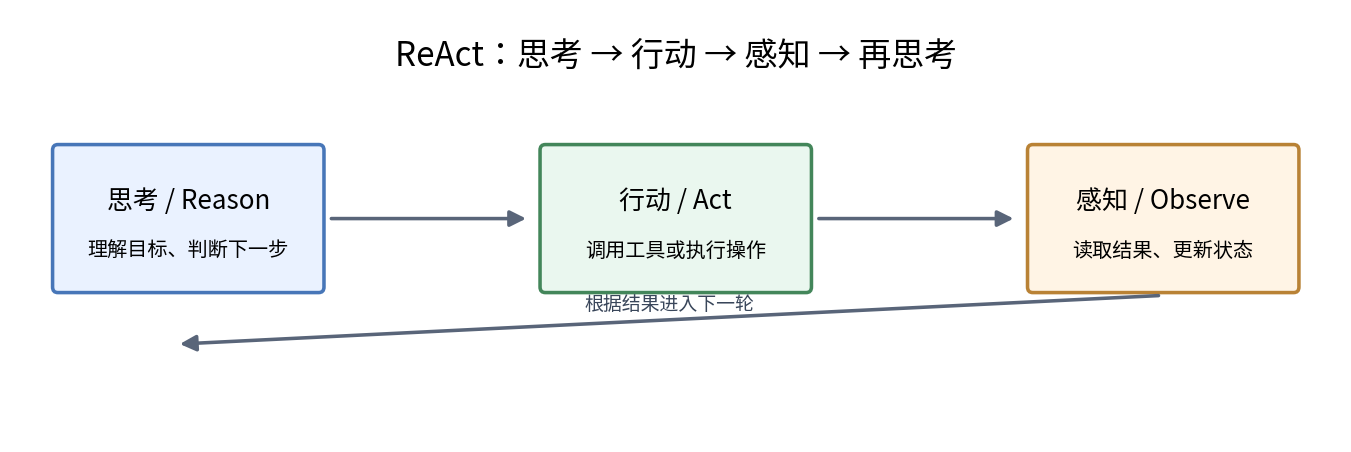

**例子：查询某城市明天的天气**

- 普通 Chat：如果没有实时天气数据，可能只能说明需要查询天气信息，或根据已有知识回答一般性问题。
- 具备天气工具的 Agent：理解“查明天的天气”这一目标 → 调用天气查询工具 → 读取返回结果 → 整理成用户能看懂的回答。

这里体现了 Agent 的关键特点：不仅生成文本，还可能与外部环境交互。是否能完成任务，取决于它是否接入了合适的工具，以及工具是否正常工作。

#### 两种常见运行思路

| 模式 | 核心思路 | 便于理解的例子 |
|---|---|---|
| ReAct | 思考 → 行动 → 感知结果，再进入下一轮 | 查天气时先判断需要天气工具，调用后根据返回数据组织回答 |
| Plan-and-Execute | 先制定步骤，再按计划逐步执行 | 整理一份资料：先读取文件，再提取重点，最后生成摘要 |

**需要记住：** ReAct 更强调行动与反馈的循环；Plan-and-Execute 更强调先规划、再执行。实际系统也可能结合使用。


### 2. 大语言模型（LLM）基础

学习笔记中将大模型的底层计算概括为大量矩阵运算。可以先把它理解为：模型把输入转换为数字表示，再通过多层计算处理信息，最终生成输出。

学习资料中涉及的技术脉络：

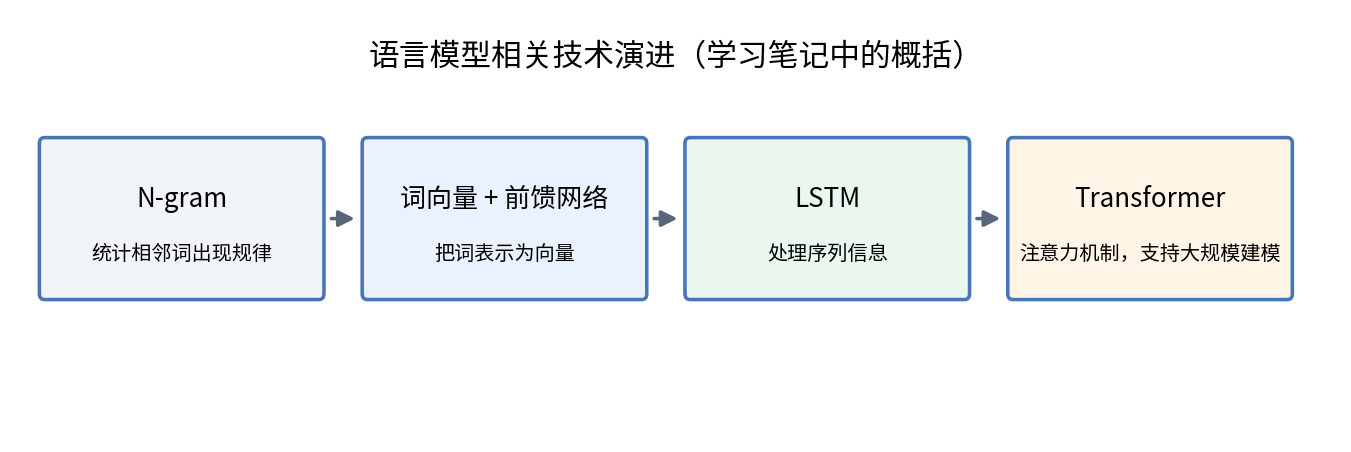

- **N-gram：** 根据前面若干个词预测下一个词，偏向统计规律。
- **词向量与前馈网络：** 将词转换成向量表示，再进行神经网络计算。
- **LSTM：** 面向序列数据，尝试保留较长距离的信息。
- **Transformer：** 通过注意力机制处理序列信息，是当前许多大语言模型的重要基础架构。

**例子：** 输入“今天天气很……”，语言模型会根据上下文计算后续 Token 的可能性，并逐步生成后面的内容。它不是简单地从数据库中取出一整句固定答案。

> 这条技术脉络是帮助我建立整体认识的简化版本，不代表每一种模型都严格按这条路线逐代替换。


### 3. Context Window、Memory 与 Prompt

这三个概念都与模型“能利用哪些信息”有关，但作用不同。

| 概念 | 我的理解 | 例子 |
|---|---|---|
| Context Window（上下文窗口） | 模型一次处理时可利用的上下文容量，有上限 | 一次对话中放入的提问、历史消息和资料不能无限增加 |
| Memory（记忆） | 将需要跨轮次保留的信息保存下来，供之后使用 | 记录项目背景或用户长期偏好，后续对话再参考 |
| System Prompt | 设定模型的角色、规则和总体要求 | “你是一名严谨的资料整理助手……” |
| User Prompt | 用户当前提出的具体任务 | “请把这份会议记录整理成三点摘要。” |

**场景例子：** 如果让 Agent 帮忙整理课程资料：
- System Prompt 规定它要忠于原文、输出结构清晰；
- User Prompt 提出“总结第三章的核心概念”；
- Context Window 中放入当前问题、相关聊天记录和本次提供的资料；
- Memory 可以保存这个学习项目的长期背景，但不等同于当前上下文窗口。

**阶段性认识：** Context 更像“当前工作台”，Memory 更像“可供以后查阅的记录”；Prompt 则是在告诉模型应该如何完成当前任务。


### 4. Tool、Skill 与 MCP

这部分是本周重点，也对应了我原始笔记中的疑问：**Agent 的工具是不是一定通过 MCP 连接？还是像安装插件一样直接安装？**

目前的理解是：并不是所有 Tool 都必须通过 MCP 接入。工具可以通过程序中的函数、API 或框架提供的集成方式接入；MCP 是一种标准化的连接协议，可以让支持该协议的 Agent 与外部工具服务按约定进行交互。

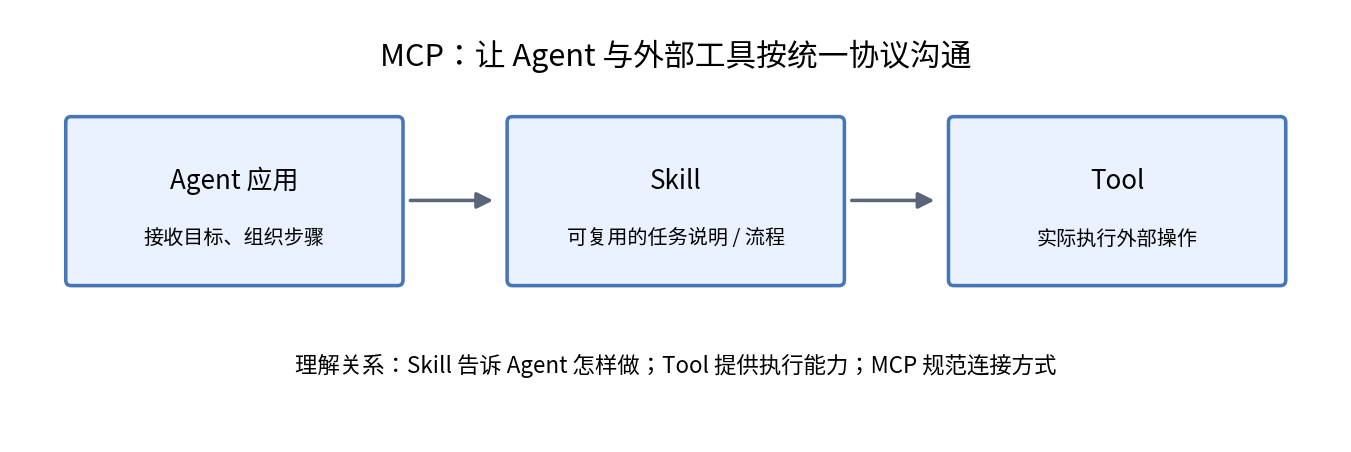

| 名称 | 主要作用 | 简单例子 |
|---|---|---|
| Tool（工具） | 提供实际执行能力 | 搜索网页、读取文件、查询天气 |
| Skill（技能） | 描述某类任务的做法和流程，便于复用 | 一份“如何整理会议纪要”的技能说明 |
| MCP | 约定 Agent 与外部工具服务之间如何沟通 | Agent 通过符合 MCP 规范的服务调用文件或数据库工具 |

#### Skill 的组成（根据本周学习资料整理）

- **元数据：** 名称（name）和描述（description），用于说明技能是什么、适合什么任务。
- **内容：** 具体的操作说明；还可能包含 reference（参考资料）或 script（脚本）。

**例子：** “会议纪要整理”Skill 可以说明整理步骤、输出格式和注意事项；真正读取文件或保存文档的动作，则可能由相应 Tool 完成。

**我目前的理解：** Skill 偏向“怎么做”，Tool 偏向“能做什么”，MCP 偏向“按什么标准连接工具”。这三者有关联，但不能混为一谈。


### 5. Token 的生成机制

Token 是模型处理文本时使用的基本单位之一。它不一定等于一个汉字、一个词或一个英文单词。不同分词器、语言和文本内容都会影响 Token 数量，因此“一个 Token 大约对应多少个汉字”只能作为非常粗略的估计，不能当成固定换算关系。

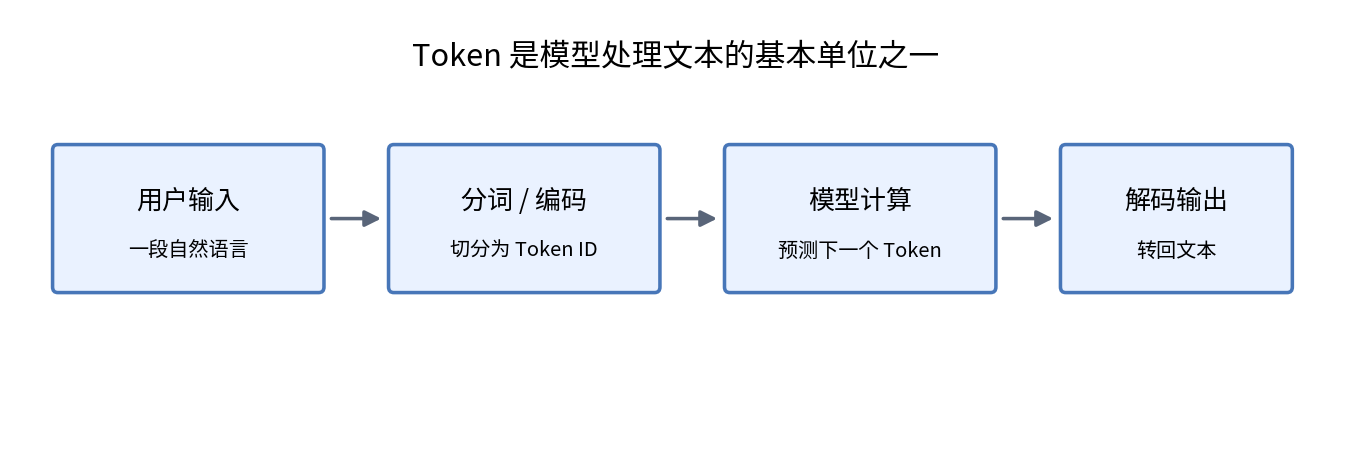

**简化流程：**

1. 用户输入一段文本；
2. 分词器按照词表和切分规则，把文本转换成 Token；
3. Token 对应的 ID 输入模型进行计算；
4. 模型逐步预测后续 Token；
5. 解码器将 Token 转换回可读文本。

**例子：** 输入“我正在学习 Agent”，分词器可能把它切成若干 Token，再转换为数字 ID。具体切分结果取决于所使用的分词器，不一定是“一个字对应一个 Token”。


### 6. RAG（检索增强生成）

**我的理解：** RAG 的核心思路是先把外部资料整理成可检索的知识库；当用户提问时，先检索与问题相关的内容，再把这些内容交给模型辅助生成回答。

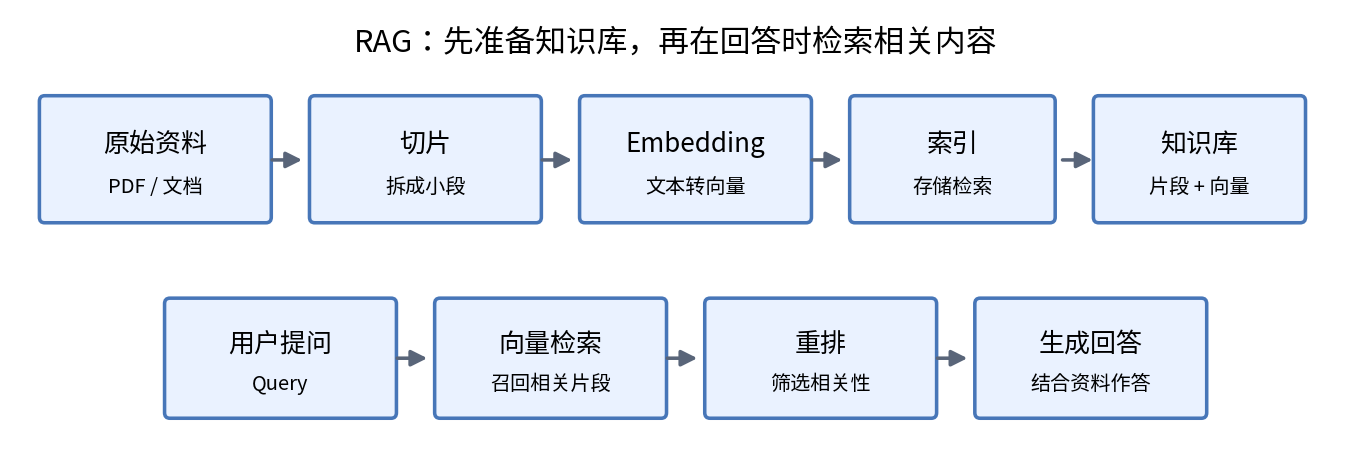

#### A. 准备阶段：建立知识库

原始资料 → 文本切片（Chunking）→ Embedding（向量化）→ 建立索引 → 保存到检索数据库。

- **切片：** 将长文档拆成较小的文本片段，方便检索。
- **Embedding：** 将文本片段转换成向量表示，便于按语义相似度查找。
- **索引：** 建立便于快速查找的结构。

#### B. 工作阶段：检索并回答

用户提问 → 对问题进行 Embedding → 召回相关片段 → 重排（Rerank）→ 将相关资料提供给模型 → 生成回答。

**完整例子：学校规章制度问答**

假设把学校的学生手册导入知识库：
1. 准备阶段先把手册拆分成若干片段并建立索引；
2. 用户问“补办学生证需要什么材料？”；
3. 系统根据问题检索可能相关的条款；
4. 对检索结果进行相关性排序；
5. 模型结合检索到的手册内容组织回答。

**为什么需要 RAG？** 当问题涉及某份特定资料、内部文档或较新的内容时，RAG 可以让回答参考检索到的资料，而不是只依赖模型原本学到的知识。检索质量和资料质量会影响最终回答。


## 三、概念之间的整体关系

把本周内容串起来，可以形成下面这条理解路径：

1. **LLM** 提供理解和生成语言的核心能力；
2. **Prompt** 告诉模型当前任务和行为要求；
3. **Context Window** 承载当前任务所需的信息，**Memory** 保存可能需要长期复用的信息；
4. **Agent** 根据目标组织思考和行动；
5. **Tool** 提供外部执行能力，**MCP** 可以规范部分工具连接方式；
6. **Skill** 将某类任务的做法整理成可复用说明；
7. **RAG** 为模型补充从外部资料中检索到的相关信息；
8. **Token** 是文本进入模型并生成输出时的重要处理单位。

这不是严格的执行顺序，而是帮助我理解各模块分工的一张知识地图。
